<a href="https://colab.research.google.com/github/Maheshwar-ap/Deep-Learning-/blob/main/deeplearning10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 19.1 MB/s eta 0:00:00
Device: cpu
Cloning StyleGAN2-ADA repository...
Repository ready!
Pretrained model ready!
Loading StyleGAN2 generator...
Generator loaded successfully!

Generating images...
10 synthetic images generated successfully!


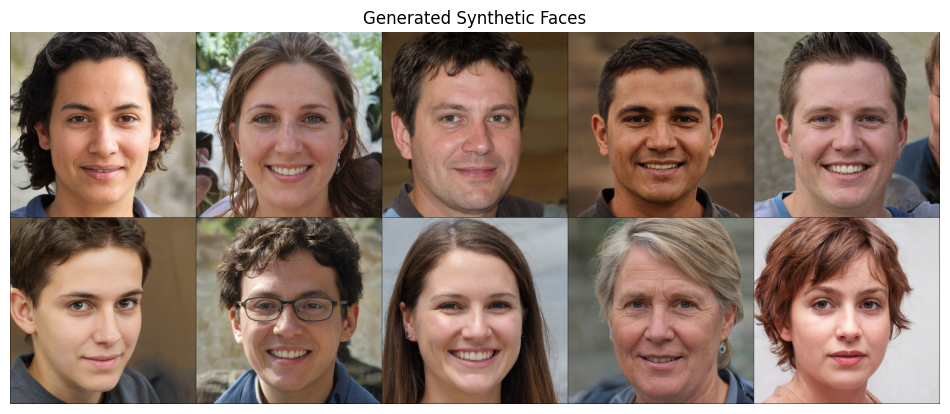


Calculating Inception Score...


/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `InceptionScore` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)


ModuleNotFoundError: InceptionScore metric requires that `Torch-fidelity` is installed. Either install as `pip install torchmetrics[image]` or `pip install torch-fidelity`.

In [ ]:
# ============================================================
# EXPERIMENT: IMAGE GENERATION USING STYLEGAN2-ADA
# Google Colab
# ============================================================

# ------------------------------------------------------------
# STEP 1: Install required libraries
# ------------------------------------------------------------

!pip install -q ninja torchmetrics pytorch-fid


# ------------------------------------------------------------
# STEP 2: Import libraries
# ------------------------------------------------------------

import os
import sys
import subprocess
import urllib.request

import torch
import torchvision
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torchvision.utils import save_image
from torch.utils.data import DataLoader

from torchmetrics.image.inception import InceptionScore


# ------------------------------------------------------------
# STEP 3: Select device
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ------------------------------------------------------------
# STEP 4: Clone StyleGAN2-ADA repository
# ------------------------------------------------------------

REPO = "stylegan2-ada-pytorch"
REPO_URL = "https://github.com/NVlabs/stylegan2-ada-pytorch.git"

if not os.path.exists(REPO):
    print("Cloning StyleGAN2-ADA repository...")
    subprocess.run(
        ["git", "clone", REPO_URL],
        check=True
    )

sys.path.append(
    os.path.abspath(REPO)
)

print("Repository ready!")


# ------------------------------------------------------------
# STEP 5: Import StyleGAN2 modules
# ------------------------------------------------------------

import legacy
import dnnlib


# ------------------------------------------------------------
# STEP 6: Download pretrained StyleGAN2 model
# ------------------------------------------------------------

MODEL_URL = (
    "https://nvlabs-fi-cdn.nvidia.com/"
    "stylegan2-ada-pytorch/pretrained/ffhq.pkl"
)

MODEL_PATH = "ffhq.pkl"

if not os.path.exists(MODEL_PATH):

    print("Downloading pretrained model...")

    urllib.request.urlretrieve(
        MODEL_URL,
        MODEL_PATH
    )

print("Pretrained model ready!")


# ------------------------------------------------------------
# STEP 7: Load pretrained generator
# ------------------------------------------------------------

print("Loading StyleGAN2 generator...")

with open(MODEL_PATH, "rb") as f:

    G = legacy.load_network_pkl(f)["G_ema"].to(device)

G.eval()

print("Generator loaded successfully!")


# ------------------------------------------------------------
# STEP 8: Generate synthetic images
# ------------------------------------------------------------

NUM_IMAGES = 10

os.makedirs(
    "generated_images",
    exist_ok=True
)

generated_images = []

print("\nGenerating images...")

with torch.no_grad():

    for i in range(NUM_IMAGES):

        # Generate random latent vector
        z = torch.randn(
            [1, G.z_dim],
            device=device
        )

        # Create label
        label = torch.zeros(
            [1, G.c_dim],
            device=device
        )

        # Generate image
        img = G(
            z,
            label,
            truncation_psi=0.5,
            noise_mode="const"
        )

        # Convert image from [-1, 1] to [0, 1]
        img = (img + 1) * 0.5

        # Save image
        save_image(
            img,
            f"generated_images/fake_{i}.png"
        )

        generated_images.append(
            img.cpu()
        )

generated_images = torch.cat(
    generated_images
)

print(
    NUM_IMAGES,
    "synthetic images generated successfully!"
)


# ------------------------------------------------------------
# STEP 9: Display generated images
# ------------------------------------------------------------

grid = torchvision.utils.make_grid(
    generated_images,
    nrow=5
)

plt.figure(figsize=(12, 5))

plt.imshow(
    grid.permute(1, 2, 0)
)

plt.axis("off")

plt.title("Generated Synthetic Faces")

plt.show()


# ------------------------------------------------------------
# STEP 10: Calculate Inception Score
# ------------------------------------------------------------

print("\nCalculating Inception Score...")

images_uint8 = (
    generated_images * 255
).clamp(
    0, 255
).to(
    torch.uint8
)

inception_metric = InceptionScore(
    normalize=False
)

inception_metric.update(
    images_uint8
)

mean, std = inception_metric.compute()

print(
    f"Inception Score: "
    f"{mean.item():.2f} ± {std.item():.2f}"
)


# ------------------------------------------------------------
# STEP 11: Download CelebA dataset
# ------------------------------------------------------------

print("\nDownloading/loading CelebA dataset...")

transform = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.ToTensor()
])

dataset = datasets.CelebA(
    root="./data",
    split="train",
    download=True,
    transform=transform
)

loader = DataLoader(
    dataset,
    batch_size=1,
    shuffle=True
)


# ------------------------------------------------------------
# STEP 12: Prepare real images
# ------------------------------------------------------------

NUM_REAL_IMAGES = 10

os.makedirs(
    "real_images",
    exist_ok=True
)

print("Preparing real images...")

for i, (img, _) in enumerate(loader):

    if i >= NUM_REAL_IMAGES:
        break

    save_image(
        img,
        f"real_images/real_{i}.png"
    )

print(
    NUM_REAL_IMAGES,
    "real images prepared!"
)


# ------------------------------------------------------------
# STEP 13: Calculate FID
# ------------------------------------------------------------

print("\nCalculating FID...")

result = subprocess.run(
    [
        "python",
        "-m",
        "pytorch_fid",
        "real_images",
        "generated_images"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print(result.stderr)


# ------------------------------------------------------------
# STEP 14: Final result
# ------------------------------------------------------------

print("\n====================================")
print("EXPERIMENT COMPLETED SUCCESSFULLY")
print("====================================")

print("Generated Images :", NUM_IMAGES)
print("Real Images      :", NUM_REAL_IMAGES)

print(
    f"Inception Score  : "
    f"{mean.item():.2f} ± {std.item():.2f}"
)

print("FID Result:")
print(result.stdout)